# Unseen LLM Annotation Results

This notebook inspects the latest LLM-generated annotations for the unseen dataset and reports label distributions for conspiracy decisions and span categories.


In [ ]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path("..").resolve()
outputs_dir = PROJECT_ROOT / "outputs"

classifications_path = outputs_dir / "llama8b-fewshot_all_classifications.csv"
spans_path = outputs_dir / "llama8b-fewshot_all_span_annotations.csv"

print(f"Classifications CSV: {classifications_path}")
print(f"Span annotations CSV: {spans_path}")

df_cls = pd.read_csv(classifications_path)
df_span = pd.read_csv(spans_path)

df_cls_head = df_cls.head()
df_span_head = df_span.head()
(df_cls_head, df_span_head)


Classifications CSV: /home/ashrafs/projects/Conspiracy-Proj/outputs/llama-3.3-70B-fewshot_un-labelled_all_classifications.csv
Span annotations CSV: /home/ashrafs/projects/Conspiracy-Proj/outputs/llama-3.3-70B-fewshot_un-labelled_all_span_annotations.csv


(  annotator_id  text_id annotation_id  \
 0          llm        0         llm_1   
 1          llm        1         llm_2   
 2          llm        2         llm_3   
 3          llm        3         llm_4   
 4          llm        4         llm_5   
 
                                                 text conspiracy  supportive  \
 0                               Well son of a bitch.         no         NaN   
 1  1/ How and why was informed consent, the bulwa...        yes         NaN   
 2  🔥 Western Hypocrisy Exposed 🔥\n\nThe protests ...        yes         NaN   
 3  Say goodbye to Fani Willis.\n\nMore to follow....         no         NaN   
 4              I turn 59 today. My, how time flies!!         no         NaN   
 
    misinformative  confidence  \
 0             NaN        0.01   
 1             NaN        0.85   
 2             NaN        0.85   
 3             NaN        0.12   
 4             NaN        0.02   
 
                                      rationale_short  
 0

In [ ]:
conspiracy_counts = (
    df_cls
    .assign(conspiracy=df_cls["conspiracy"].str.strip().str.lower())
    .groupby("conspiracy")
    .size()
    .rename("count")
    .reset_index()
    .sort_values("count", ascending=False)
)

conspiracy_counts


,conspiracy,count
0,no,1680
1,yes,980


Text(0, 0.5, 'Count')

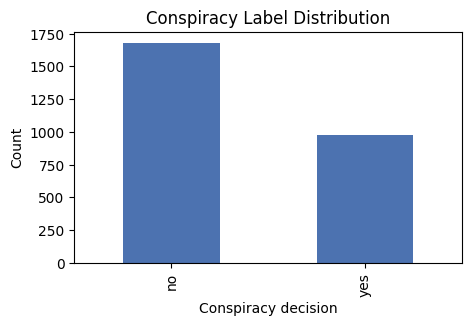

In [ ]:
ax = conspiracy_counts.plot.bar(x="conspiracy", y="count", legend=False, figsize=(5, 3), color="#4C72B0")
ax.set_title("Conspiracy Label Distribution")
ax.set_xlabel("Conspiracy decision")
ax.set_ylabel("Count")


In [ ]:
span_label_map = {
    "plan": "plan_event",
    "secret": "secret",
    "out-group": "out_group",
    "in-group": "in_group",
    "call-to-action": "call_to_action",
}

span_counts = {}
for col, label in span_label_map.items():
    tokens = (
        df_span[col]
        .dropna()
        .str.split(r"\s*\|\|\s*")
        .apply(lambda items: [item.strip() for item in items if item and item.strip()])
    )
    span_counts[label] = tokens.explode().shape[0]

span_counts_series = pd.Series(span_counts).rename_axis("label").rename("count")
span_counts_df = span_counts_series.reset_index().sort_values("count", ascending=False)
span_counts_df


,label,count
0,plan_event,1785
2,out_group,967
1,secret,793
3,in_group,362
4,call_to_action,254


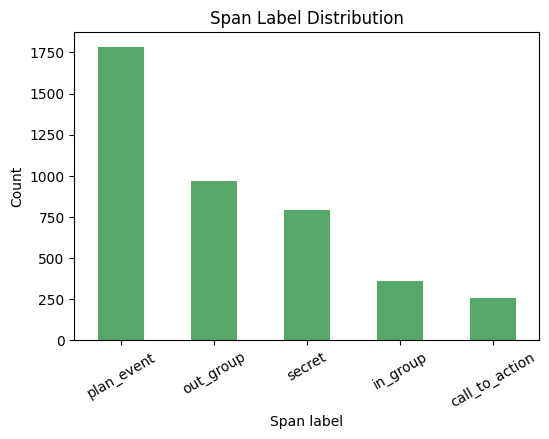

In [ ]:
ax = span_counts_df.plot.bar(x="label", y="count", legend=False, figsize=(6, 4), color="#55A868")
ax.set_title("Span Label Distribution")
ax.set_xlabel("Span label")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=30)
